# HASTS206 Assignment 2: Part 4: District clustering

**All data are hypothetical (synthetic).** Run from the repository root. The first code cell runs the previous part (`part5_markov.ipynb`) so that all earlier variables exist.

In [ ]:
%run part5_markov.ipynb

## 4. District clustering
### 4(a) Data preparation
One row per district with: share under 15, share aged 65+ (1 Jan 2025), 2025 net migration rate (per 1,000 mean-stock residents) and piped-water access (%).

**Imputation rule for the two missing water values (primary fit).** I use a **3-nearest-neighbour imputation on the other three standardised demographic features** (the water value is the average of the 3 most similar districts with observed water). *Justification:* water access is strongly associated with the demographic profile (see the correlations below), so a global mean or median would pull D04 (young profile, probably low access) and D17 (in-migration profile, probably high access) towards the middle and blur the clusters. Neighbour imputation retains all 24 districts, uses only information available for the district, and is transparent. Sensitivity checks with the global median and with dropping water are run in 4(c).

In [34]:
# What this cell does: Builds one row per district with four features (under-15 share, 65+ share, net
# migration rate, piped water) and fills the two missing water values with the average of the 3 most
# similar districts.
feat = struct[['share_u15', 'share_65p']].copy()
feat['net_migration_rate'] = 1000 * (districts.set_index('district_id').arrivals_2025 - districts.set_index('district_id').departures_2025) / ((pop25 + pop26) / 2)
feat['piped_water_pct'] = districts.set_index('district_id').piped_water_pct
feat = feat.astype(float)
print('Missing values:', feat.isna().sum().to_dict(), '->', feat.index[feat.piped_water_pct.isna()].tolist())
print('\nCorrelation of water with the other features (observed districts only):'); print(feat.corr().piped_water_pct.round(3).to_string())

others = ['share_u15', 'share_65p', 'net_migration_rate']
Z3 = (feat[others] - feat[others].mean()) / feat[others].std(ddof=0)
obs = feat.piped_water_pct.notna()
feat['water_imputed'] = ~obs
feat_imp = feat.copy()
for d in feat.index[~obs]:
    dist = np.sqrt(((Z3[obs] - Z3.loc[d]) ** 2).sum(axis=1)).sort_values()
    nn = dist.index[:3]
    feat_imp.loc[d, 'piped_water_pct'] = feat.loc[nn, 'piped_water_pct'].mean()
    print(f'{d}: nearest neighbours {list(nn)} with water {feat.loc[nn,"piped_water_pct"].tolist()} -> imputed {feat_imp.loc[d,"piped_water_pct"]:.1f}%  (global median would be {feat.piped_water_pct.median():.1f}%)')
FEATS = ['share_u15', 'share_65p', 'net_migration_rate', 'piped_water_pct']
feat_imp[FEATS].describe().T[['count', 'mean', 'std', 'min', 'max']]

Missing values: {'share_u15': 0, 'share_65p': 0, 'net_migration_rate': 0, 'piped_water_pct': 2} -> ['D04', 'D17']

Correlation of water with the other features (observed districts only):
share_u15            -0.6490
share_65p            -0.2250
net_migration_rate    0.8650
piped_water_pct            1
D04: nearest neighbours ['D22', 'D16', 'D13'] with water [44.2, 35.8, 27.7] -> imputed 35.9%  (global median would be 54.0%)
D17: nearest neighbours ['D05', 'D11', 'D08'] with water [77.4, 70.4, 72.9] -> imputed 73.6%  (global median would be 54.0%)


,count,mean,std,min,max
share_u15,24,0.1712,0.0869,0.0903,0.2996
share_65p,24,0.1835,0.0696,0.1222,0.2863
net_migration_rate,24,2.5219,6.8611,-3.9426,13.9906
piped_water_pct,24,56.2319,18.2673,27.7000,86.5000


**Notes: building the clustering table and filling the gaps.**
- Water access is strongly linked to the other features (correlation 0.87 with the net migration rate and -0.65 with the under-15 share). So filling gaps with similar districts is more sensible than using one global value.
- The 3-nearest-neighbour rule gives **D04 = 35.9%** (its neighbours are young districts with low access) and **D17 = 73.6%** (its neighbours are in-migration districts with high access). The overall median (54.0%) would have put both in the middle. Both imputed values are flagged and we check them again in the stability tests.

Districts with |z| > 2.5 on any feature: []
Districts outside 1.5xIQR fences on any feature: [] (IQR fences are not informative for a deliberately bimodal/trimodal feature)
Max |z| per feature: {'share_u15': 1.51, 'share_65p': 1.51, 'net_migration_rate': 1.71, 'piped_water_pct': 1.69}
Standardised matrix: means [0.0, 0.0, 0.0, 0.0]  sd [1.0, 1.0, 1.0, 1.0]


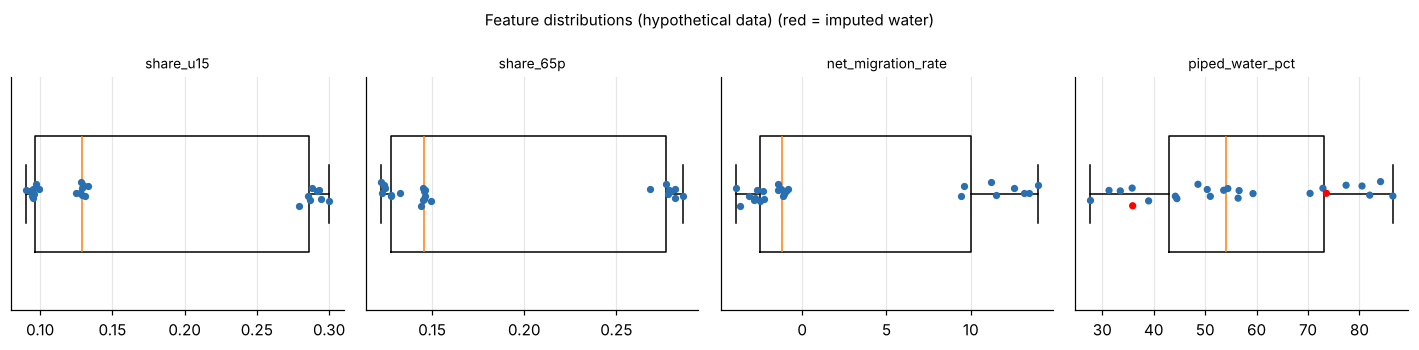

In [35]:
# What this cell does: Checks for outliers with z-scores and the 1.5 x IQR rule, then standardises all
# four features to mean 0 and standard deviation 1.
# Outlier checks on the imputed feature set: |z| > 2.5 and Tukey 1.5 x IQR fences
scaler = StandardScaler()
Xz = pd.DataFrame(scaler.fit_transform(feat_imp[FEATS]), index=feat_imp.index, columns=FEATS)
q1, q3 = feat_imp[FEATS].quantile(.25), feat_imp[FEATS].quantile(.75); iqr = q3 - q1
fence = ((feat_imp[FEATS] < q1 - 1.5 * iqr) | (feat_imp[FEATS] > q3 + 1.5 * iqr))
print('Districts with |z| > 2.5 on any feature:', Xz.index[(Xz.abs() > 2.5).any(axis=1)].tolist())
print('Districts outside 1.5xIQR fences on any feature:', fence.index[fence.any(axis=1)].tolist(), '(IQR fences are not informative for a deliberately bimodal/trimodal feature)')
print('Max |z| per feature:', Xz.abs().max().round(2).to_dict())
print('Standardised matrix: means', Xz.mean().round(6).tolist(), ' sd', Xz.std(ddof=0).round(6).tolist())
fig, ax = plt.subplots(1, 4, figsize=(13, 3.2))
for a, c in zip(ax, FEATS):
    a.boxplot(feat_imp[c], vert=False, widths=.5); a.scatter(feat_imp[c], np.random.default_rng(1).normal(1, .04, len(feat_imp)), s=14, c=np.where(feat.water_imputed, 'red', '#2a6fb0') if c == 'piped_water_pct' else '#2a6fb0', zorder=3); a.set_title(c, fontsize=9); a.set_yticks([])
fig.suptitle(f'Feature distributions {HYP} (red = imputed water)', fontsize=10); fig.tight_layout()

**Notes: outliers, standardising and why the ID is dropped.** No district has |z| above 2.5 (the largest is 1.71) and none is outside the 1.5 x IQR fences, so we remove nothing. Standardising is essential because net migration (-4 to +14) and water access (28 to 87) would otherwise swamp the shares (0.09 to 0.30). The district ID (D01 to D24) is a label, not a measurement. Its order is arbitrary, so using it as a number would invent distances, and one-hot coding would make every district equally far from every other and add 24 useless columns. We use the ID only afterwards to name the results.

**Why the district identifier is excluded.** `district_id` (D01 to D24) is a label, not a measurement. Treated as a number its order is arbitrary and would inject meaningless distance (D01 would look "close" to D02 only because of the sort order); one-hot encoding would make every district equidistant from every other and add 24 uninformative dimensions. Clusters should come from demographic and service features only. The ID is used afterwards to *label* the results. `region` is also excluded from the fit because it is a reporting label; it is cross-tabulated afterwards as a validity check.

### 4(b) k-means diagnostics, k = 1 to 6
Each fit uses `n_init = 25` random initialisations and keeps the lowest within-cluster sum of squares (WCSS). Silhouette is undefined for k = 1.

,k,WCSS,reduction_from_previous_%,mean_silhouette,min_cluster_size
0,1,96,NaN,NaN,24
1,2,42.7161,55.5041,0.5950,8
2,3,2.5675,93.9894,0.8639,8
3,4,1.6048,37.4972,0.7834,4
4,5,1.0390,35.2557,0.6372,3
5,6,0.8082,22.2177,0.4739,3


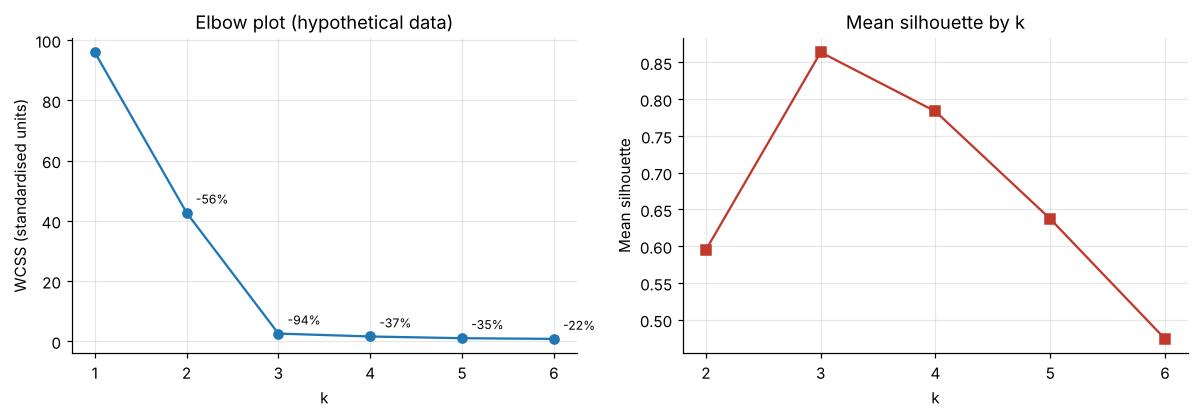

In [36]:
# What this cell does: Runs k-means for k = 1 to 6 (25 starts each), records WCSS, the percentage fall
# between successive k, and the mean silhouette for k = 2 to 6, then plots the elbow and silhouette
# curves.
X = Xz.values
fits = {k: KMeans(n_clusters=k, n_init=25, random_state=42).fit(X) for k in range(1, 7)}
diag = pd.DataFrame({'k': list(fits), 'WCSS': [f.inertia_ for f in fits.values()]})
diag['reduction_from_previous_%'] = 100 * (1 - diag.WCSS / diag.WCSS.shift(1))
diag['mean_silhouette'] = [np.nan] + [silhouette_score(X, fits[k].labels_) for k in range(2, 7)]
diag['min_cluster_size'] = [np.bincount(f.labels_).min() for f in fits.values()]
diag.to_csv(OUT / 'cluster_diagnostics.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
ax[0].plot(diag.k, diag.WCSS, 'o-'); ax[0].set_xlabel('k'); ax[0].set_ylabel('WCSS (standardised units)'); ax[0].set_title(f'Elbow plot {HYP}')
for k, w, r in zip(diag.k, diag.WCSS, diag['reduction_from_previous_%']):
    if k > 1: ax[0].annotate(f'-{r:.0f}%', (k, w), textcoords='offset points', xytext=(6, 6), fontsize=8)
ax[0].set_xticks(range(1, 7)); ax[1].set_xticks(range(2, 7)); ax[1].plot(diag.k[1:], diag.mean_silhouette[1:], 's-', color='#c0392b'); ax[1].set_xlabel('k'); ax[1].set_ylabel('Mean silhouette'); ax[1].set_title('Mean silhouette by k')
fig.tight_layout(); fig.savefig(FIG / 'cluster_diagnostics.png', dpi=150)
diag

**Notes: WCSS and silhouette.**
- **WCSS** is the total squared distance from each district to its cluster centre. It always goes down when k goes up (it starts at 96 for k = 1), so we look for the elbow. The percentage falls are 55.5% (k = 2), **94.0% (k = 3)**, and then 37.5%, 35.3%, 22.2%. The drop at k = 3 is by far the biggest, so the elbow is at 3.
- **Mean silhouette** for k = 2 to 6: 0.595, **0.864**, 0.783, 0.637, 0.474. It peaks at k = 3.

k=3: mean silhouette 0.864; min 0.794; districts with silhouette < 0.25: 0; negative: 0
k=4: mean silhouette 0.783; min 0.476; districts with silhouette < 0.25: 0; negative: 0


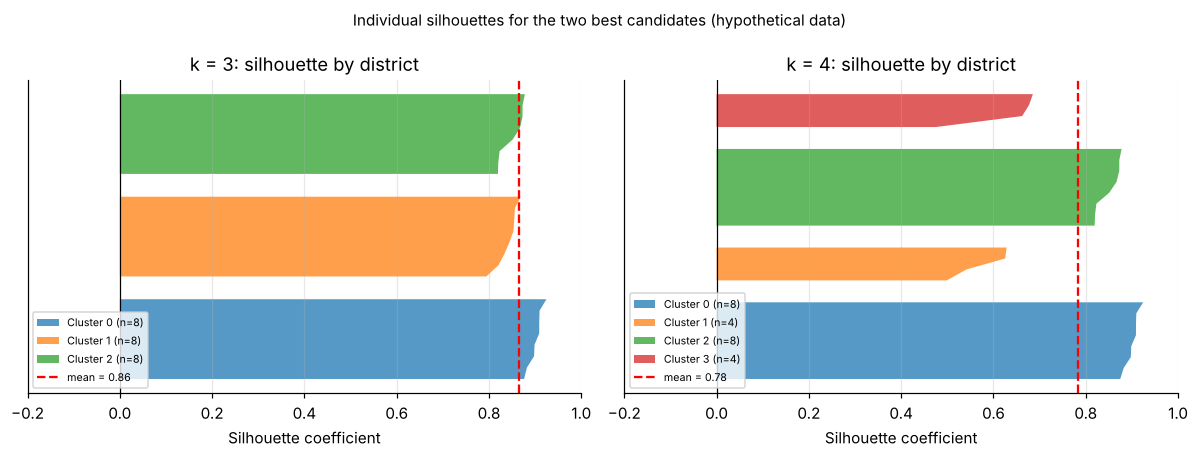

In [37]:
# What this cell does: Draws the individual silhouette of every district for the two best candidate
# values of k (3 and 4).
def silhouette_plot(k, ax):
    lab = fits[k].labels_; s = silhouette_samples(X, lab); y0 = 0
    for c in range(k):
        sc = np.sort(s[lab == c]); ax.fill_betweenx(np.arange(y0, y0 + len(sc)), 0, sc, alpha=.75, label=f'Cluster {c} (n={len(sc)})'); y0 += len(sc) + 1
    ax.axvline(s.mean(), color='r', ls='--', label=f'mean = {s.mean():.2f}'); ax.axvline(0, color='k', lw=.8)
    ax.set_title(f'k = {k}: silhouette by district'); ax.set_xlabel('Silhouette coefficient'); ax.set_yticks([]); ax.legend(fontsize=7, loc='lower left'); ax.set_xlim(-.2, 1)
cand = diag.iloc[1:].sort_values('mean_silhouette', ascending=False).k.head(2).astype(int).tolist()
cand = sorted(cand)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for k, a in zip(cand, axes): silhouette_plot(k, a)
fig.suptitle(f'Individual silhouettes for the two best candidates {HYP}', fontsize=10); fig.tight_layout(); fig.savefig(FIG / 'cluster_silhouettes.png', dpi=150)
for k in cand:
    s = silhouette_samples(X, fits[k].labels_)
    print(f'k={k}: mean silhouette {s.mean():.3f}; min {s.min():.3f}; districts with silhouette < 0.25: {int((s<.25).sum())}; negative: {int((s<0).sum())}')

**Notes: individual silhouettes.** A silhouette compares how close a district is to its own cluster with how close it is to the next nearest cluster. Near +1 means it fits well. **Near zero means it is on the border.** **Negative means it is nearer another cluster than its own**, which signals a bad assignment or a split that should not exist. For k = 3 every district scores high (lowest 0.794, none negative). For k = 4 the lowest falls to 0.476, which shows that one natural group is being cut in two for no good reason. At k = 2 two clearly different groups are forced together (mean 0.595).

### 4(c) Choice of k, stability and profiles

In [38]:
# What this cell does: Fixes k = 3 and tests stability: four different random seeds, dropping the
# water feature, using the median instead of neighbour imputation, deleting D04 and D17, and comparing
# with k = 4. Uses the adjusted Rand index (ARI).
K = 3
base_lab = fits[K].labels_
# ---- stability 1: different seeds
rows = []
for sd in [1, 7, 123, 2026]:
    lab = KMeans(n_clusters=K, n_init=25, random_state=sd).fit_predict(X)
    rows.append(dict(check=f'Different seed (random_state={sd})', n_districts=24, ARI_vs_primary=adjusted_rand_score(base_lab, lab)))
# ---- stability 2: feature selection (drop water, so no imputation needed)
X3 = StandardScaler().fit_transform(feat_imp[others])
lab3 = KMeans(n_clusters=K, n_init=25, random_state=42).fit_predict(X3)
rows.append(dict(check='Drop piped water (3 features)', n_districts=24, ARI_vs_primary=adjusted_rand_score(base_lab, lab3)))
# ---- stability 3: missing-value treatment: global median
fm = feat[FEATS].copy(); fm['piped_water_pct'] = fm.piped_water_pct.fillna(fm.piped_water_pct.median())
labm = KMeans(n_clusters=K, n_init=25, random_state=42).fit_predict(StandardScaler().fit_transform(fm))
rows.append(dict(check='Global-median water imputation', n_districts=24, ARI_vs_primary=adjusted_rand_score(base_lab, labm)))
# ---- stability 4: drop the two districts with missing water (22 common districts)
keep = obs.values
lab22 = KMeans(n_clusters=K, n_init=25, random_state=42).fit_predict(StandardScaler().fit_transform(feat[FEATS][keep]))
rows.append(dict(check='Listwise deletion of D04, D17', n_districts=int(keep.sum()), ARI_vs_primary=adjusted_rand_score(base_lab[keep], lab22)))
# ---- stability 5: neighbouring k (does k=4 split a coherent group?)
lab4 = fits[4].labels_
rows.append(dict(check='k = 4 vs k = 3 (partition refinement)', n_districts=24, ARI_vs_primary=adjusted_rand_score(base_lab, lab4)))
stab = pd.DataFrame(rows)
KEY['stab'] = stab.round(4).to_dict('records')
stab

,check,n_districts,ARI_vs_primary
0,Different seed (random_state=1),24,1
1,Different seed (random_state=7),24,1
2,Different seed (random_state=123),24,1
3,Different seed (random_state=2026),24,1
4,Drop piped water (3 features),24,1
5,Global-median water imputation,24,1
6,"Listwise deletion of D04, D17",22,1
7,k = 4 vs k = 3 (partition refinement),24,0.8553


**Notes: choosing k and checking stability.**
- **We choose k = 3.** *Diagnostics:* it has the biggest WCSS elbow (a fall of 94%) and the best mean silhouette (0.864) with no weak districts. *Meaning:* the three clusters are easy to describe (young and growing, working-age with in-migration and good services, and old and shrinking). k = 2 merges two of these and k = 4 creates a cluster of only 4 districts with no new demographic story.
- **Stability:** the grouping is identical (ARI = 1) under four different seeds, with water dropped, with median imputation, and with D04 and D17 deleted (compared on the 22 common districts). The k = 4 result is lower because it splits one of the three groups. So the membership does not depend on the seed, on how we filled the water gaps, or on including water at all.

In [39]:
# What this cell does: Fits the final 3-cluster solution, names the clusters from their centroids,
# reports sizes and centroids in the original units, and compares clusters with the four regions.
res = feat_imp[FEATS + ['water_imputed']].copy(); res['cluster_raw'] = base_lab
cen_raw = res.groupby('cluster_raw')[FEATS].mean()
order = {}
young = cen_raw.share_u15.idxmax(); old = cen_raw.share_65p.idxmax(); rest = [c for c in cen_raw.index if c not in (young, old)][0]
order = {young: 'C1 Young, natural-increase', rest: 'C2 Working-age, in-migration, well-served', old: 'C3 Ageing, net out-migration'}
res['cluster'] = res.cluster_raw.map(order)
res['region'] = districts.set_index('district_id').region
res['silhouette'] = silhouette_samples(X, base_lab)
cent = res.groupby('cluster')[FEATS].mean(); cent.insert(0, 'n_districts', res.groupby('cluster').size())
cent['piped_water_pct (observed only)'] = feat.groupby(res.cluster).piped_water_pct.mean()
cent['mean_silhouette'] = res.groupby('cluster').silhouette.mean()
print('Cluster sizes and centroids in ORIGINAL units (primary fit, k=3):'); print(cent.round(3).to_string())
inv = pd.DataFrame(scaler.inverse_transform(fits[K].cluster_centers_), columns=FEATS, index=[order[i] for i in range(K)]).loc[cent.index]
print('\nCheck: centroids from inverse_transform equal group means:', np.allclose(inv.values, cent[FEATS].values))
print('\nMembership:'); [print(f'  {c}: ', ', '.join(res.index[res.cluster == c])) for c in cent.index]
print('\nRegion vs cluster (clusters are not simply the reporting regions):'); print(pd.crosstab(res.cluster, res.region).to_string())
KEY['clusters'] = dict(centroids=cent.round(4).to_dict('index'), members={c: res.index[res.cluster == c].tolist() for c in cent.index}, imputed=feat_imp.loc[~obs, 'piped_water_pct'].round(1).to_dict(),
                       diag=diag.round(4).to_dict('records'))

Cluster sizes and centroids in ORIGINAL units (primary fit, k=3):
                                           n_districts  share_u15  share_65p  net_migration_rate  piped_water_pct  piped_water_pct (observed only)  mean_silhouette
cluster                                                                                                                                                            
C1 Young, natural-increase                           8     0.2900     0.1460             -2.7580          36.4880                          36.5710           0.8500
C2 Working-age, in-migration, well-served            8     0.1290     0.1260             11.8600          78.4210                          79.1140           0.8410
C3 Ageing, net out-migration                         8     0.0950     0.2790             -1.5360          53.7880                          53.7880           0.9010

Check: centroids from inverse_transform equal group means: True

Membership:
  C1 Young, natural-increase:  D01, 

**Notes: the cluster profiles in real units.**
- **C1, Young, natural-increase (8 districts):** 29.0% under 15, 14.6% aged 65+, net migration -2.8 per 1,000, piped water 36.5%. **C2, Working-age, in-migration, well-served (8):** 12.9%, 12.6%, 11.9, 78.4%. **C3, Ageing, net out-migration (8):** 9.5%, 27.9%, -1.5, 53.8%.
- Every cluster has members from all four regions, so the clusters are not just the reporting regions.
- **One use:** target different programmes at different profiles, for example water and school or maternal-health investment in C1, housing and infrastructure for newcomers in C2, and elderly care and health access in C3. A new district could be given a first-pass profile by assigning it to the nearest centroid.
- **One limitation:** the profiles are single-year district averages of four features. They hide differences inside districts and do not tell us causes (low water access could be because a district is rural, not because it is young). The separation is unusually clean because the data are made up, and with only 24 districts a different feature set could change real results. The imputed water values for D04 and D17 are the least certain numbers in the profiles.

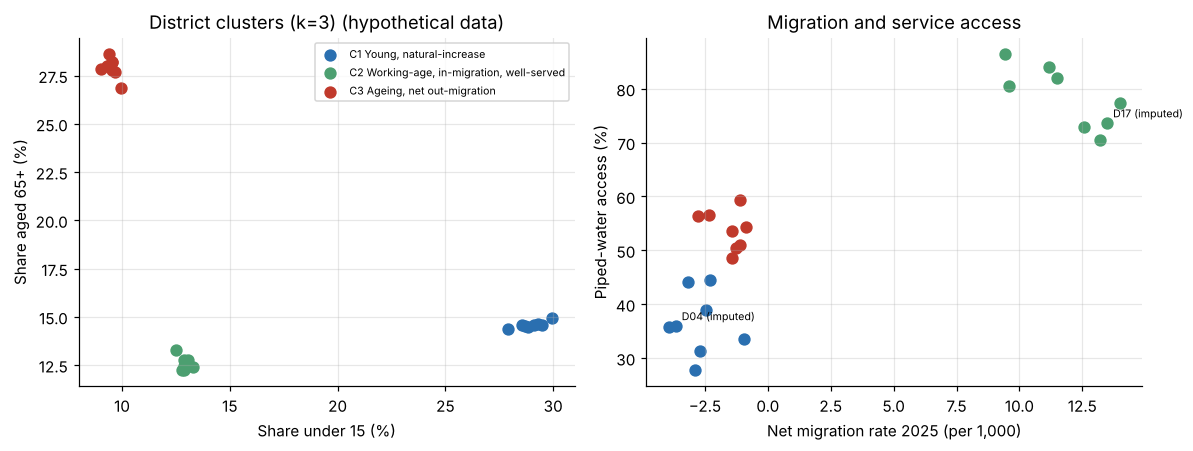

In [40]:
# What this cell does: Draws the clusters in two scatter plots (shares under 15 and 65+, and migration
# against water access) with the imputed districts marked.
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
pal = {'C1 Young, natural-increase': '#2a6fb0', 'C2 Working-age, in-migration, well-served': '#4c9f70', 'C3 Ageing, net out-migration': '#c0392b'}
for c, g in res.groupby('cluster'):
    ax[0].scatter(g.share_u15 * 100, g.share_65p * 100, c=pal[c], label=c, s=50)
    ax[1].scatter(g.net_migration_rate, g.piped_water_pct, c=pal[c], s=50, marker='o')
    for d in g.index[g.water_imputed]: ax[1].annotate(d + ' (imputed)', (g.loc[d, 'net_migration_rate'], g.loc[d, 'piped_water_pct']), fontsize=7, xytext=(4, 4), textcoords='offset points')
ax[0].set_xlabel('Share under 15 (%)'); ax[0].set_ylabel('Share aged 65+ (%)'); ax[0].legend(fontsize=7); ax[0].set_title(f'District clusters (k=3) {HYP}')
ax[1].set_xlabel('Net migration rate 2025 (per 1,000)'); ax[1].set_ylabel('Piped-water access (%)'); ax[1].set_title('Migration and service access')
fig.tight_layout(); fig.savefig(FIG / 'clusters.png', dpi=150)
res.reset_index().to_csv(OUT / 'cluster_results.csv', index=False); cent.reset_index().to_csv(OUT / 'cluster_centroids.csv', index=False)

**Notes: the cluster plots.** In the left plot the three groups sit far apart, with no district in between. In the right plot the in-migration districts (C2) separate from the rest, and D04 and D17 (the imputed ones) sit with their own cluster's neighbours, which is a good sign that the imputation was sensible.